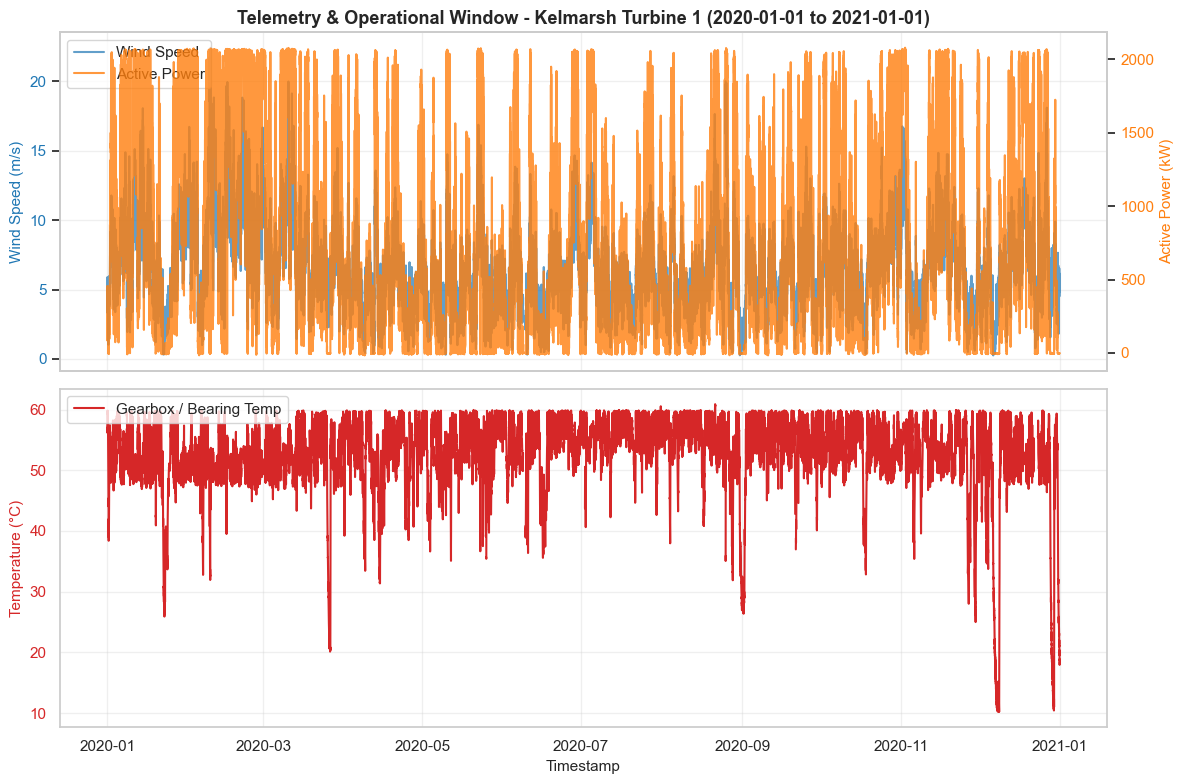

In [ ]:
import sys
from pathlib import Path

# Add root directory to path
sys.path.append(str(Path.cwd().parent))

from src.data_loader import load_scada_data
from src.plotting import plot_scada_timeseries_anomaly
import matplotlib.pyplot as plt

# 1. Load data
data_file = Path("../data/Turbine_Data_Kelmarsh_1_2020-01-01_-_2021-01-01.csv")

try:
    df = load_scada_data(data_file)
    
    # 2. Select a representative multi-day window (adjust dates to match your dataset's timeframe)
    # Example: A 7-day window in January 2019
    start_date = '2020-01-01'
    end_date = '2021-01-01'
    
    # 3. Generate multi-axis telemetry plot
    # Note: Adjust column names if your Kelmarsh file uses alternative headers for temperature
    fig, axes = plot_scada_timeseries_anomaly(
        df, 
        start_time=start_date, 
        end_time=end_date,
        power_col='Power (kW)',
        temp_col='Gear oil temperature (°C)', # Or 'GenBearingTemp_Avg' depending on available columns
        wind_col='Wind speed (m/s)',
        turbine_name='Kelmarsh Turbine 1'
    )
    
    plt.show()
    
except Exception as e:
    print(f"Verify dataset path and column names. Error details: {e}")